# Apartment Size Classes

<div dir="rtl">

متراژ آپارتمان یک عدد پیوسته است، ولی خریدار و مستأجر معمولاً با دسته‌هایی مثل «کوچک‌متراژ» یا «بزرگ» دنبال خانه می‌گردند. متراژ را به چهار دسته تبدیل می‌کنیم و بررسی می‌کنیم که قیمت هر متر در این دسته‌ها چه تغییری می‌کند.

انتظار رایج این است که واحدهای بزرگ‌تر، مثل خرید عمده، قیمت هر متر کمتری داشته باشند.

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal

df = pd.read_parquet('divar_clean.parquet',
                     columns=['cat3_slug', 'city_slug', 'building_size', 'rooms_count', 'price_per_m2'])
apt = df[df['cat3_slug'].isin(['apartment-sell', 'apartment-rent'])].copy()

# price per m2 compared with the typical apartment of the same city and deal
apt['relative_price'] = apt['price_per_m2'] / apt.groupby(['city_slug', 'cat3_slug'])['price_per_m2'].transform('median')

In [2]:
labels = ['small (<60)', 'medium (60-100)', 'large (100-150)', 'very large (150+)']
apt['size_class'] = pd.cut(apt['building_size'], [0, 60, 100, 150, float('inf')], right=False, labels=labels)

sale = apt[apt['cat3_slug'] == 'apartment-sell']
sale.groupby('size_class', observed=True).agg(
    ads=('size_class', 'size'),
    median_rooms=('rooms_count', 'median'),
    median_relative_price=('relative_price', 'median')).round(2)

,ads,median_rooms,median_relative_price
size_class,,,
small (<60),36543,1.0,0.80
medium (60-100),136058,2.0,0.91
large (100-150),91374,2.0,1.12
very large (150+),38096,3.0,1.52


<div dir="rtl">

تعداد اتاق‌ها هم با این دسته‌ها جور درمی‌آید: کوچک‌متراژها معمولاً یک‌خوابه‌اند، متوسط و بزرگ دوخوابه، و خیلی بزرگ‌ها سه‌خوابه. ولی قیمت نسبی برخلاف انتظار با بزرگ‌تر شدن واحد بالا می‌رود، نه پایین.

</div>

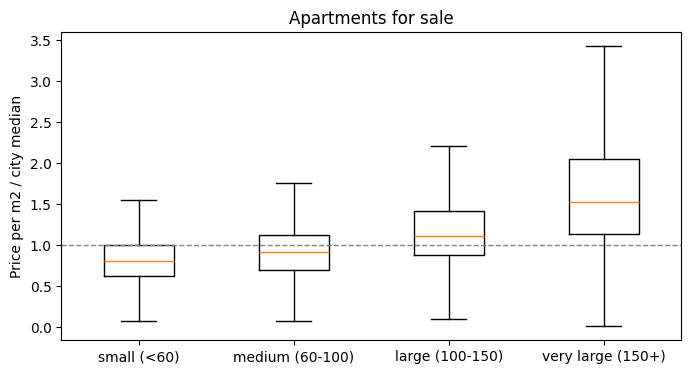

In [3]:
data = [sale.loc[sale['size_class'] == c, 'relative_price'].dropna() for c in labels]
plt.figure(figsize=(8, 4))
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, 5), labels)
plt.axhline(1, color='grey', ls='--', lw=1)
plt.ylabel('Price per m2 / city median')
plt.title('Apartments for sale')
plt.show()

## Test

<div dir="rtl">

فرض صفر: توزیع قیمت نسبی هر متر در چهار دسته‌ی متراژ یکسان است. آزمون Kruskal-Wallis را هم برای فروش و هم برای اجاره انجام می‌دهیم و اندازه‌ی اثر را با ε² می‌سنجیم.

</div>

In [4]:
for cat in ['apartment-sell', 'apartment-rent']:
    part = apt[apt['cat3_slug'] == cat]
    groups = [g.dropna() for _, g in part.groupby('size_class', observed=True)['relative_price']]
    h, p = kruskal(*groups)
    n = sum(len(g) for g in groups)
    eps2 = (h - len(groups) + 1) / (n - len(groups))
    medians = part.groupby('size_class', observed=True)['relative_price'].median().round(2).tolist()
    print(f'{cat}: p-value = {p:.2g}, epsilon squared = {eps2:.2f}, medians = {medians}')

apartment-sell: p-value = 0, epsilon squared = 0.19, medians = [0.8, 0.91, 1.12, 1.52]
apartment-rent: p-value = 0, epsilon squared = 0.14, medians = [0.85, 0.92, 1.06, 1.37]


<div dir="rtl">

در هر دو حالت فرض صفر رد می‌شود و اثر در حد متوسط است. در فروش، هر متر از آپارتمان‌های بالای ۱۵۰ متر حدود دو برابر کوچک‌متراژهای همان شهر قیمت دارد. در اجاره هم همین الگو دیده می‌شود، فقط کمی ملایم‌تر.

پس در این بازار واحد بزرگ کالای لوکس است، نه خرید عمده. برای قیمت‌گذاری یعنی نمی‌شود قیمت هر متر یک شهر را در متراژ ضرب کرد. برای سیستم توصیه‌گر هم دسته‌ی متراژ یک فیلتر معنادار است، چون هر دسته هم نیاز خانوار متفاوتی دارد و هم سطح قیمت متفاوتی.

</div>